# Notebook 1: Sequential Data and the RNN Idea
**Phase 3, Day 1**

In this notebook: (1) an RNN cell written by hand in NumPy, (2) sliding windows, a time-based split and correct scaling, (3) a naive baseline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Part 1: An RNN cell by hand (NumPy)
Formula: `h_t = tanh(W_x x_t + W_h h_{t-1} + b)`

The **same weights** are used at every time step.

In [2]:
input_size, hidden_size, T = 3, 4, 6

# Random weights, shared across all time steps
W_x = np.random.randn(hidden_size, input_size) * 0.5
W_h = np.random.randn(hidden_size, hidden_size) * 0.5
b   = np.zeros(hidden_size)

def rnn_cell(x_t, h_prev):
    return np.tanh(W_x @ x_t + W_h @ h_prev + b)

# One sequence: T steps, 3 features per step
x = np.random.randn(T, input_size)

h = np.zeros(hidden_size)          # h_0 = zeros
hidden_states = []
for t in range(T):
    h = rnn_cell(x[t], h)
    hidden_states.append(h)
    print(f"t={t+1}  h_t = {np.round(h, 3)}")

hidden_states = np.array(hidden_states)
print("\nShape of hidden states:", hidden_states.shape, "(time, hidden)")

t=1  h_t = [-0.313 -0.339 -0.418  0.045]
t=2  h_t = [0.637 0.947 0.899 0.788]
t=3  h_t = [-0.9   -0.375 -0.04  -0.033]
t=4  h_t = [-0.038 -0.727 -0.991 -0.029]
t=5  h_t = [0.934 0.731 0.615 0.618]
t=6  h_t = [-0.905 -0.78  -0.425 -0.023]

Shape of hidden states: (6, 4) (time, hidden)


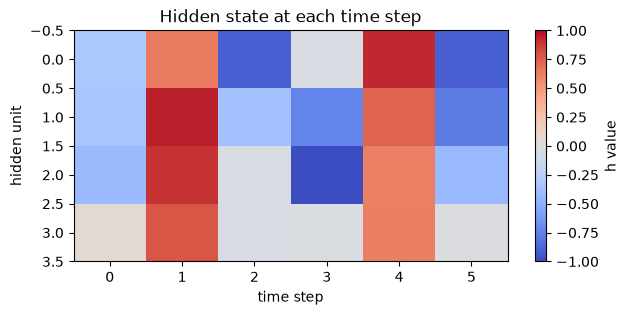

In [3]:
plt.figure(figsize=(7, 3))
plt.imshow(hidden_states.T, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='h value')
plt.xlabel('time step'); plt.ylabel('hidden unit')
plt.title('Hidden state at each time step')
plt.show()

**Observation (write in your own words):** the hidden state at each step is built from both the previous state and the new input, which is why an RNN has a form of 'memory'.

## Part 2: Preparing time-series data

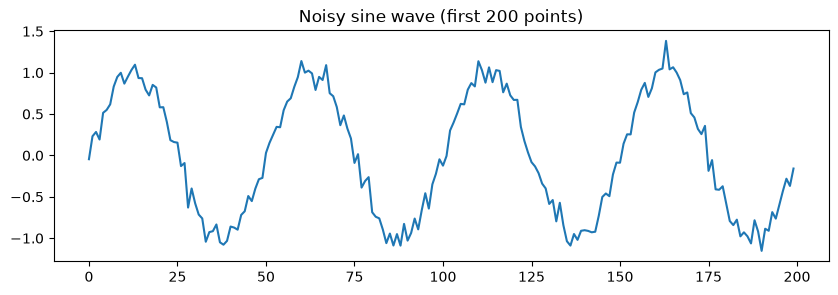

In [4]:
# Noisy sine wave
n = 1000
t = np.arange(n)
series = np.sin(2 * np.pi * t / 50) + 0.1 * np.random.randn(n)

plt.figure(figsize=(10, 3))
plt.plot(series[:200])
plt.title('Noisy sine wave (first 200 points)')
plt.show()

In [5]:
# Split by time (never shuffle): 70% train, 15% validation, 15% test
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
train_raw = series[:n_train]
val_raw   = series[n_train:n_train + n_val]
test_raw  = series[n_train + n_val:]
print(len(train_raw), len(val_raw), len(test_raw))

# Scaling: mean/std from the training part ONLY
mean, std = train_raw.mean(), train_raw.std()
train = (train_raw - mean) / std
val   = (val_raw   - mean) / std
test  = (test_raw  - mean) / std
print("train mean/std (scaled):", round(train.mean(), 3), round(train.std(), 3))

700 150 150
train mean/std (scaled): 0.0 1.0


In [6]:
def make_windows(data, k):
    """Use the previous k values to predict the next one."""
    X, y = [], []
    for i in range(len(data) - k):
        X.append(data[i:i + k])
        y.append(data[i + k])
    return np.array(X), np.array(y)

k = 20
X_train, y_train = make_windows(train, k)
X_val,   y_val   = make_windows(val, k)
X_test,  y_test  = make_windows(test, k)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "X_test:", X_test.shape)

X_train: (680, 20) y_train: (680,)
X_val:   (130, 20) X_test: (130, 20)


## Part 3: Naive baseline
Rule: **tomorrow = today**. Every model has to beat this.

Naive  VAL : MAE=0.1686  RMSE=0.2145
Naive  TEST: MAE=0.1824  RMSE=0.2294


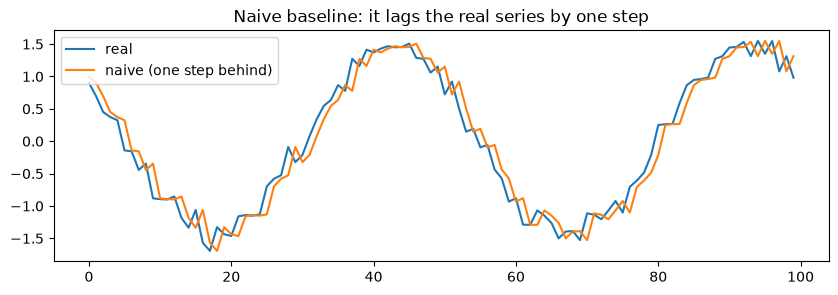

In [7]:
def mae(a, b):  return np.mean(np.abs(a - b))
def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))

# Naive prediction = the last value of the window
naive_val  = X_val[:, -1]
naive_test = X_test[:, -1]

print(f"Naive  VAL : MAE={mae(y_val, naive_val):.4f}  RMSE={rmse(y_val, naive_val):.4f}")
print(f"Naive  TEST: MAE={mae(y_test, naive_test):.4f}  RMSE={rmse(y_test, naive_test):.4f}")

plt.figure(figsize=(10, 3))
plt.plot(y_test[:100], label='real')
plt.plot(naive_test[:100], label='naive (one step behind)')
plt.legend(); plt.title('Naive baseline: it lags the real series by one step')
plt.show()

## Summary (write in your own words)
- What an RNN cell does:
- Why we split by time and scale with training statistics only:
- The naive baseline score (remember it, we compare against it on Day 2):